In [39]:

# ==========================================
# 1. IMPORT LIBRARY
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

# ==========================================
# 2. UPLOAD DATASET
# ==========================================

uploaded = files.upload()

file_name = next(iter(uploaded))

# Membaca CSV tanpa menetapkan header
raw = pd.read_csv(file_name, header=None, dtype=str)

print("Dataset berhasil dimuat!")
print("Nama file:", file_name)
print("Ukuran data mentah:", raw.shape)


Saving Rata-rata Konsumsi Perkapita Seminggu Menurut Kelompok Buah-Buahan Per Kabupaten_Kota-Komoditas 2025, 2025.csv to Rata-rata Konsumsi Perkapita Seminggu Menurut Kelompok Buah-Buahan Per Kabupaten_Kota-Komoditas 2025, 2025 (3).csv
Dataset berhasil dimuat!
Nama file: Rata-rata Konsumsi Perkapita Seminggu Menurut Kelompok Buah-Buahan Per Kabupaten_Kota-Komoditas 2025, 2025 (3).csv
Ukuran data mentah: (518, 26)


In [ ]:

# ==========================================
# 3. MEMPERBAIKI STRUKTUR DATASET
# ==========================================

# Mengambil nama kolom dari baris ketiga
kolom = ["Kabupaten/Kota"] + raw.iloc[2, 2:].tolist()

# Mengambil data mulai baris kelima
df = raw.iloc[4:, [0] + list(range(2, 26))].copy()

# Memberikan nama kolom
df.columns = kolom

# Menghapus spasi pada nama wilayah
df["Kabupaten/Kota"] = df["Kabupaten/Kota"].str.strip()

# Mengubah tanda '-' menjadi missing value
fitur = kolom[1:]

df[fitur] = df[fitur].replace("-", np.nan)

# Mengubah fitur menjadi numerik
for col in fitur:
    df[col] = pd.to_numeric(
        df[col].str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Menghapus kolom yang seluruh nilainya konstan
kolom_konstan = [
    col for col in fitur
    if df[col].nunique(dropna=False) <= 1
]

print("Kolom konstan:", kolom_konstan)

df = df.drop(columns=kolom_konstan)

# Reset index
df = df.reset_index(drop=True)

print("\nUkuran dataset setelah perapian:", df.shape)
display(df.head())


Kolom konstan: []

Ukuran dataset setelah perapian: (514, 25)


,Kabupaten/Kota,"Jeruk, jeruk bali",Mangga,Apel,Rambutan,"Duku, langsat",Durian,Salak,Pisang ambon,Pisang lainnya,...,Nanas,Nangka,Pir,Anggur,Buah naga,Jambu air,Melon,Manggis,Kelengkeng,Buah-buahan lainnya
0,Simeulue,0.037,0.004,0.001,0.018,0.006,0.004,0.031,0.010,0.149,...,0.005,0.009,0.014,0.000,0.002,0.028,NaN,0.001,0.002,0.015
1,Aceh Singkil,0.152,0.003,0.011,0.015,0.048,0.001,0.095,0.006,0.062,...,0.013,0.002,0.030,0.003,0.006,0.004,0.003,0.000,0.006,0.003
2,Aceh Selatan,0.112,0.012,0.010,0.013,0.022,0.040,0.083,0.013,0.062,...,0.010,0.002,0.021,0.003,0.008,0.010,0.001,0.001,0.001,0.013
3,Aceh Tenggara,0.102,0.008,0.012,0.009,0.021,0.000,0.063,0.006,0.053,...,0.012,0.001,0.036,0.002,0.010,0.008,NaN,0.000,0.002,0.007
4,Aceh Timur,0.128,0.021,0.008,0.027,0.044,0.003,0.080,0.007,0.019,...,0.020,0.002,0.016,0.005,0.006,0.013,NaN,0.007,0.004,0.001


In [ ]:

# ==========================================
# 4. INFORMASI DATASET
# ==========================================

print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

print("\nInformasi tipe data:")
df.info()

print("\nJumlah data kosong:")
print(df.isnull().sum())

print("\nJumlah data duplikat:")
print(df.duplicated().sum())

print("\nStatistik deskriptif:")
display(df.describe().T)


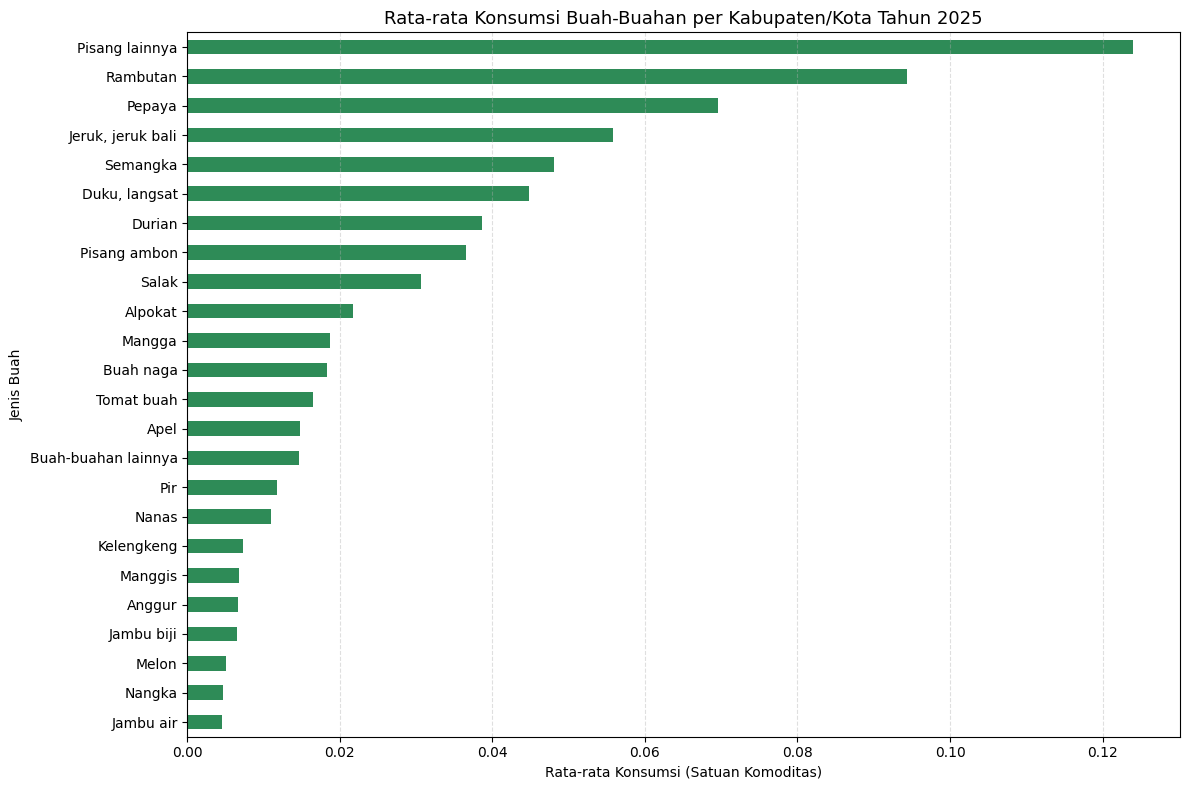

Lima jenis buah dengan rata-rata tertinggi:


,Rata-rata
Pisang lainnya,0.123961
Rambutan,0.094347
Pepaya,0.069569
"Jeruk, jeruk bali",0.055864
Semangka,0.048061


Lima jenis buah dengan rata-rata terendah:


,Rata-rata
Anggur,0.006603
Jambu biji,0.006553
Melon,0.005089
Nangka,0.004695
Jambu air,0.004546


In [ ]:

# ==========================================
# 2.1 DISTRIBUSI FITUR KONSUMSI BUAH
# ==========================================

# Mengambil seluruh fitur numerik
fitur = df.select_dtypes(include=np.number).columns.tolist()

# Menghitung rata-rata setiap jenis buah
rata_rata_buah = df[fitur].mean().sort_values(
    ascending=False
)

# Membuat grafik
plt.figure(figsize=(12, 8))

rata_rata_buah.sort_values().plot(
    kind="barh",
    color="seagreen"
)

plt.title(
    "Rata-rata Konsumsi Buah-Buahan per Kabupaten/Kota Tahun 2025",
    fontsize=13
)
plt.xlabel("Rata-rata Konsumsi (Satuan Komoditas)")
plt.ylabel("Jenis Buah")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Menampilkan lima jenis buah tertinggi
print("Lima jenis buah dengan rata-rata tertinggi:")
display(rata_rata_buah.head(5).to_frame("Rata-rata"))

# Menampilkan lima jenis buah terendah
print("Lima jenis buah dengan rata-rata terendah:")
display(rata_rata_buah.tail(5).to_frame("Rata-rata"))


Berdasarkan grafik distribusi rata-rata konsumsi buah-buahan, diketahui bahwa pisang lainnya memiliki nilai rata-rata konsumsi tertinggi sebesar 0,123961, diikuti oleh rambutan sebesar 0,094347 dan pepaya sebesar 0,069569. Sementara itu, jambu air memiliki rata-rata konsumsi terendah sebesar 0,004546. Hasil ini menunjukkan bahwa terdapat perbedaan pola konsumsi antara berbagai jenis buah pada kabupaten/kota di Indonesia.


In [ ]:

# ==========================================
# 2.2 HEATMAP KORELASI
# ==========================================

# Menghitung korelasi antarfitur numerik
korelasi = df[fitur].corr(method="pearson")

# Membuat heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    korelasi,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    annot_kws={"size": 7}
)

plt.title(
    "Heatmap Korelasi Konsumsi Buah-Buahan Tahun 2025",
    fontsize=14
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Menampilkan hubungan antarfitur terkuat
korelasi_pasangan = korelasi.where(
    np.triu(np.ones(korelasi.shape), k=1).astype(bool)
).stack().sort_values(ascending=False)

print("Lima pasangan fitur dengan korelasi positif tertinggi:")
display(korelasi_pasangan.head(5))


Berdasarkan heatmap korelasi, terdapat hubungan positif antara beberapa jenis buah. Korelasi tertinggi ditemukan pada pasangan jeruk dan pir sebesar 0,740, sedangkan pasangan apel dan anggur memiliki korelasi sebesar 0,685. Hal ini menunjukkan bahwa pada wilayah yang memiliki nilai konsumsi lebih tinggi untuk salah satu jenis buah tersebut, jenis buah pasangannya cenderung memiliki nilai konsumsi yang lebih tinggi pula. Namun, korelasi tidak menunjukkan hubungan sebab-akibat.

In [ ]:

# ==========================================
# 2.3 BOXPLOT IDENTIFIKASI OUTLIER
# ==========================================

plt.figure(figsize=(16, 9))

data_boxplot = df[fitur].melt(
    var_name="Jenis Buah",
    value_name="Konsumsi"
)

sns.boxplot(
    data=data_boxplot,
    x="Konsumsi",
    y="Jenis Buah",
    color="lightgreen",
    showfliers=True
)

plt.title(
    "Boxplot Distribusi Konsumsi Buah-Buahan Tahun 2025",
    fontsize=14
)

plt.xlabel("Rata-rata Konsumsi")
plt.ylabel("Jenis Buah")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


Berdasarkan visualisasi boxplot, dapat diamati bahwa persebaran nilai konsumsi berbeda pada setiap jenis buah. Beberapa jenis buah seperti durian, rambutan, dan duku memiliki rentang nilai yang relatif lebih besar dibandingkan beberapa jenis buah lainnya. Terdapat pula beberapa titik yang berpotensi menjadi outlier. Kondisi tersebut menunjukkan adanya perbedaan nilai konsumsi antarwilayah yang perlu diperiksa lebih lanjut pada tahap pra-pemrosesan data. Outlier tidak langsung dihapus karena nilai ekstrem dapat mencerminkan karakteristik konsumsi suatu wilayah.

In [ ]:

# ==========================================
# 2.4 VISUALISASI MISSING VALUE
# ==========================================

missing = df[fitur].isnull().sum().sort_values(
    ascending=False
)

missing = missing[missing > 0]

plt.figure(figsize=(12, 7))

missing.sort_values().plot(
    kind="barh",
    color="coral"
)

plt.title(
    "Jumlah Missing Value pada Setiap Jenis Buah",
    fontsize=14
)

plt.xlabel("Jumlah Missing Value")
plt.ylabel("Jenis Buah")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Total missing value:", df[fitur].isnull().sum().sum())
print(
    "Jumlah wilayah dengan missing value:",
    df[fitur].isnull().any(axis=1).sum()
)

:::writing{variant="document" id="61386"}
Berdasarkan visualisasi missing value, diketahui bahwa terdapat nilai kosong pada beberapa jenis buah. Jumlah missing value tertinggi terdapat pada melon sebanyak 132 data dan manggis sebanyak 124 data. Secara keseluruhan, terdapat 642 nilai kosong yang tersebar pada 221 kabupaten/kota. Kondisi ini menunjukkan bahwa dataset memerlukan proses penanganan missing value sebelum digunakan dalam pemodelan K-Means.
:::

In [ ]:

# ==========================================
# 3.1 PERSIAPAN DATA
# ==========================================

# Membuat salinan dataset
df_preprocessing = df.copy()

# Memisahkan kolom wilayah dan fitur numerik
kolom_wilayah = "Kabupaten/Kota"

fitur = df_preprocessing.select_dtypes(
    include=np.number
).columns.tolist()

print("Jumlah data:", df_preprocessing.shape[0])
print("Jumlah fitur numerik:", len(fitur))

print("\nDaftar fitur:")
print(fitur)

display(df_preprocessing.head())


Jumlah data: 514
Jumlah fitur numerik: 24

Daftar fitur:
['Jeruk, jeruk bali', 'Mangga', 'Apel', 'Rambutan', 'Duku, langsat', 'Durian', 'Salak', 'Pisang ambon', 'Pisang lainnya', 'Pepaya', 'Semangka', 'Tomat buah', 'Alpokat', 'Jambu biji', 'Nanas', 'Nangka', 'Pir', 'Anggur', 'Buah naga', 'Jambu air', 'Melon', 'Manggis', 'Kelengkeng', 'Buah-buahan lainnya']


,Kabupaten/Kota,"Jeruk, jeruk bali",Mangga,Apel,Rambutan,"Duku, langsat",Durian,Salak,Pisang ambon,Pisang lainnya,...,Nanas,Nangka,Pir,Anggur,Buah naga,Jambu air,Melon,Manggis,Kelengkeng,Buah-buahan lainnya
0,Simeulue,0.037,0.004,0.001,0.018,0.006,0.004,0.031,0.010,0.149,...,0.005,0.009,0.014,0.000,0.002,0.028,NaN,0.001,0.002,0.015
1,Aceh Singkil,0.152,0.003,0.011,0.015,0.048,0.001,0.095,0.006,0.062,...,0.013,0.002,0.030,0.003,0.006,0.004,0.003,0.000,0.006,0.003
2,Aceh Selatan,0.112,0.012,0.010,0.013,0.022,0.040,0.083,0.013,0.062,...,0.010,0.002,0.021,0.003,0.008,0.010,0.001,0.001,0.001,0.013
3,Aceh Tenggara,0.102,0.008,0.012,0.009,0.021,0.000,0.063,0.006,0.053,...,0.012,0.001,0.036,0.002,0.010,0.008,NaN,0.000,0.002,0.007
4,Aceh Timur,0.128,0.021,0.008,0.027,0.044,0.003,0.080,0.007,0.019,...,0.020,0.002,0.016,0.005,0.006,0.013,NaN,0.007,0.004,0.001


In [ ]:

# ==========================================
# 3.2 PEMERIKSAAN MISSING VALUE
# ==========================================

# Menghitung missing value setiap fitur
missing = df_preprocessing[fitur].isnull().sum()

# Membuat tabel missing value
tabel_missing = pd.DataFrame({
    "Jumlah Missing Value": missing,
    "Persentase (%)": (
        missing / len(df_preprocessing) * 100
    )
})

tabel_missing = tabel_missing.sort_values(
    by="Jumlah Missing Value",
    ascending=False
)

display(tabel_missing)

print(
    "\nTotal missing value:",
    df_preprocessing[fitur].isnull().sum().sum()
)


Berdasarkan hasil pemeriksaan, ditemukan 642 nilai kosong pada fitur konsumsi buah. Nilai kosong tersebut tersebar pada 221 kabupaten/kota.

Kondisi ini menunjukkan bahwa dataset belum sepenuhnya lengkap sehingga perlu dilakukan penanganan sebelum digunakan dalam proses clustering.

In [ ]:

# ==========================================
# 3.3 PENANGANAN MISSING VALUE
# ==========================================

from sklearn.impute import SimpleImputer

# Membuat objek imputasi median
imputer = SimpleImputer(strategy="median")

# Mengisi missing value
data_imputasi = imputer.fit_transform(
    df_preprocessing[fitur]
)

# Mengubah kembali menjadi DataFrame
df_imputasi = pd.DataFrame(
    data_imputasi,
    columns=fitur,
    index=df_preprocessing.index
)

# Memeriksa kembali missing value
print(
    "Missing value setelah imputasi:",
    df_imputasi.isnull().sum().sum()
)

display(df_imputasi.head())


Berdasarkan hasil pemeriksaan missing value, ditemukan sebanyak 642 nilai kosong pada beberapa fitur konsumsi buah. Untuk menangani permasalahan tersebut, digunakan metode Median Imputation dengan mengganti nilai kosong menggunakan nilai median dari masing-masing fitur. Metode median dipilih karena lebih tahan terhadap pengaruh nilai ekstrem dibandingkan rata-rata. Setelah proses imputasi dilakukan, seluruh nilai kosong pada fitur numerik berhasil ditangani sehingga dataset dapat dilanjutkan ke tahap berikutnya.

In [ ]:

# ==========================================
# 3.4 PEMERIKSAAN DATA DUPLIKAT
# ==========================================

# Memeriksa duplikasi seluruh baris
jumlah_duplikat = df_preprocessing.duplicated().sum()

# Memeriksa duplikasi nama wilayah
duplikat_wilayah = (
    df_preprocessing[kolom_wilayah].duplicated().sum()
)

print("Jumlah baris duplikat:", jumlah_duplikat)
print("Jumlah nama wilayah duplikat:", duplikat_wilayah)


Jumlah baris duplikat: 0
Jumlah nama wilayah duplikat: 0


In [ ]:

# ==========================================
# 3.5 IDENTIFIKASI OUTLIER DENGAN IQR
# ==========================================

# Menghitung Q1 dan Q3
Q1 = df_imputasi.quantile(0.25)
Q3 = df_imputasi.quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Menghitung batas bawah dan batas atas
batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

# Mendeteksi outlier
outlier = (
    (df_imputasi < batas_bawah) |
    (df_imputasi > batas_atas)
)

# Menghitung jumlah outlier setiap fitur
jumlah_outlier = outlier.sum()

tabel_outlier = pd.DataFrame({
    "Jumlah Outlier": jumlah_outlier,
    "Persentase (%)": (
        jumlah_outlier / len(df_imputasi) * 100
    )
})

tabel_outlier = tabel_outlier.sort_values(
    by="Jumlah Outlier",
    ascending=False
)

display(tabel_outlier)

print(
    "Total nilai yang terdeteksi sebagai outlier:",
    outlier.sum().sum()
)


In [ ]:

# ==========================================
# 3.6 PENANGANAN OUTLIER DENGAN IQR CAPPING
# ==========================================

# Membatasi nilai berdasarkan batas IQR
df_outlier = df_imputasi.clip(
    lower=batas_bawah,
    upper=batas_atas,
    axis=1
)

# Menghitung kembali outlier setelah capping
outlier_setelah = (
    (df_outlier < batas_bawah) |
    (df_outlier > batas_atas)
)

print(
    "Jumlah outlier sebelum capping:",
    outlier.sum().sum()
)

print(
    "Jumlah outlier setelah capping:",
    outlier_setelah.sum().sum()
)

print("Jumlah baris setelah capping:", len(df_outlier))

display(df_outlier.head())


In [ ]:

# ==========================================
# 3.7 SCALING DENGAN STANDARDSCALER
# ==========================================

from sklearn.preprocessing import StandardScaler

# Membuat objek StandardScaler
scaler = StandardScaler()

# Melakukan scaling
data_scaled = scaler.fit_transform(df_outlier)

# Mengubah hasil scaling menjadi DataFrame
df_scaled = pd.DataFrame(
    data_scaled,
    columns=fitur,
    index=df_outlier.index
)

print("Data sebelum scaling:")
display(df_outlier.head())

print("\nData setelah scaling:")
display(df_scaled.head())

# Memeriksa rata-rata dan standar deviasi
print("\nRata-rata setelah scaling:")
print(df_scaled.mean().round(3))

print("\nStandar deviasi setelah scaling:")
print(df_scaled.std().round(3))


In [ ]:

# ==========================================
# 3.8 PERSIAPAN DATA UNTUK CLUSTERING
# ==========================================

# Menyimpan nama wilayah
nama_wilayah = df_preprocessing[kolom_wilayah].copy()

# Memastikan ukuran dataset
print("Data tanpa scaling:", df_outlier.shape)
print("Data dengan scaling:", df_scaled.shape)
print("Jumlah wilayah:", len(nama_wilayah))

# Memeriksa missing value
print(
    "Missing value tanpa scaling:",
    df_outlier.isnull().sum().sum()
)

print(
    "Missing value dengan scaling:",
    df_scaled.isnull().sum().sum()
)

# Memastikan tidak ada nilai tak hingga
print(
    "Nilai infinite:",
    np.isinf(df_scaled.to_numpy()).sum()
)


In [ ]:

# ==========================================
# TAHAP 4: PEMODELAN K-MEANS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Memastikan SEED sesuai NIM
SEED = 118

# Menentukan rentang jumlah cluster
rentang_k = range(2, 9)

print("Jumlah data:", len(df_outlier))
print("Jumlah fitur:", df_outlier.shape[1])
print("SEED:", SEED)


Jumlah data: 514
Jumlah fitur: 24
SEED: 118


In [ ]:

# ==========================================
# K-MEANS TANPA SCALING
# ==========================================

hasil_tanpa_scaling = []

for k in rentang_k:

    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    )

    label_cluster = model.fit_predict(df_outlier)

    inertia = model.inertia_
    silhouette = silhouette_score(
        df_outlier,
        label_cluster
    )

    hasil_tanpa_scaling.append({
        "k": k,
        "Inertia": inertia,
        "Silhouette": silhouette
    })

tabel_tanpa_scaling = pd.DataFrame(hasil_tanpa_scaling)

display(tabel_tanpa_scaling)


,k,Inertia,Silhouette
0,2,7.076844,0.252107
1,3,5.808662,0.206031
2,4,5.235398,0.187585
3,5,4.725719,0.180310
4,6,4.352214,0.192581
5,7,4.136257,0.181028
6,8,3.964232,0.176935


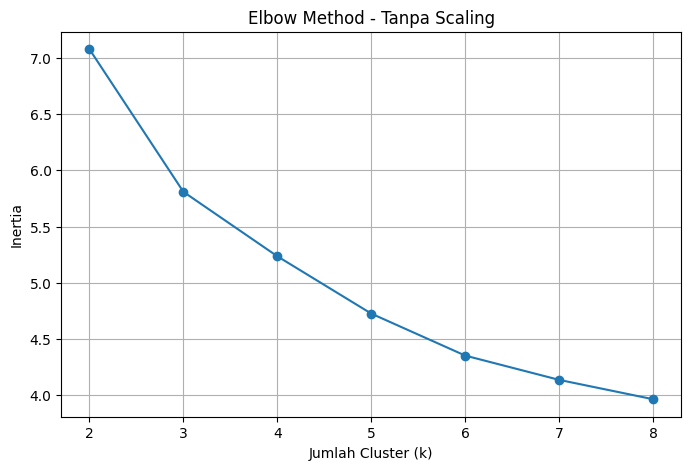

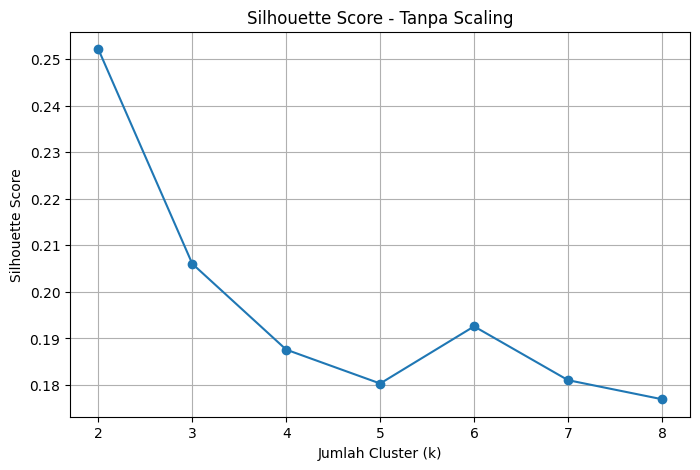

In [ ]:

# Grafik Elbow tanpa scaling
plt.figure(figsize=(8, 5))

plt.plot(
    tabel_tanpa_scaling["k"],
    tabel_tanpa_scaling["Inertia"],
    marker="o"
)

plt.title("Elbow Method - Tanpa Scaling")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.xticks(list(rentang_k))
plt.grid(True)
plt.show()


# Grafik Silhouette tanpa scaling
plt.figure(figsize=(8, 5))

plt.plot(
    tabel_tanpa_scaling["k"],
    tabel_tanpa_scaling["Silhouette"],
    marker="o"
)

plt.title("Silhouette Score - Tanpa Scaling")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(rentang_k))
plt.grid(True)
plt.show()


In [ ]:

# ==========================================
# K-MEANS DENGAN SCALING
# ==========================================

hasil_dengan_scaling = []

for k in rentang_k:

    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    )

    label_cluster = model.fit_predict(df_scaled)

    inertia = model.inertia_
    silhouette = silhouette_score(
        df_scaled,
        label_cluster
    )

    hasil_dengan_scaling.append({
        "k": k,
        "Inertia": inertia,
        "Silhouette": silhouette
    })

tabel_dengan_scaling = pd.DataFrame(hasil_dengan_scaling)

display(tabel_dengan_scaling)


,k,Inertia,Silhouette
0,2,10766.638091,0.119558
1,3,9702.232406,0.137583
2,4,9015.438437,0.141623
3,5,8601.097640,0.125999
4,6,8282.783244,0.123776
5,7,8040.458480,0.104201
6,8,7800.559189,0.118186


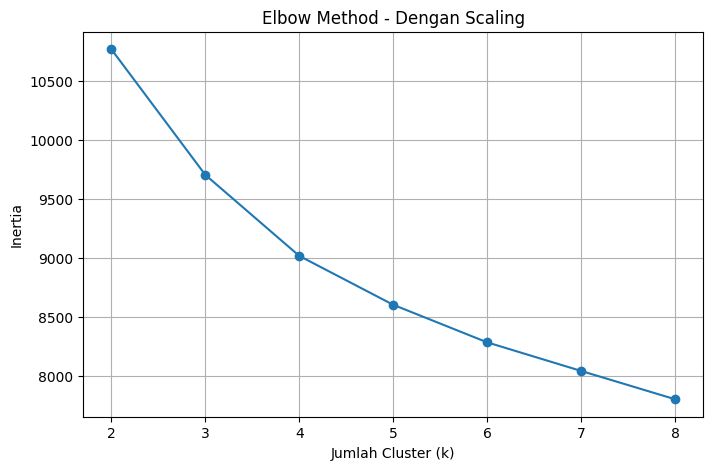

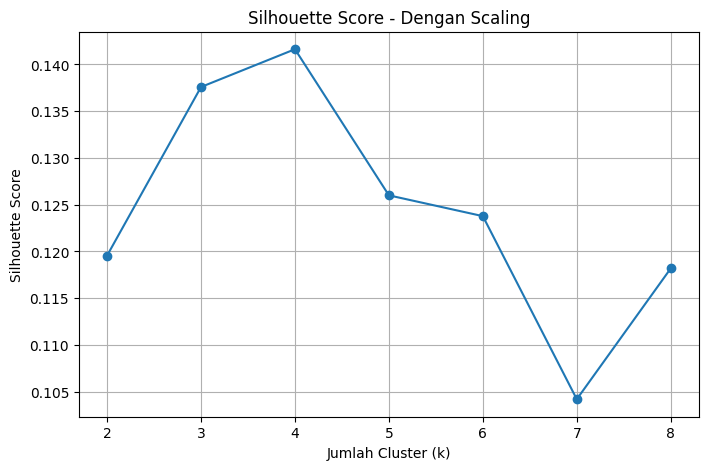

In [ ]:

# Grafik Elbow dengan scaling
plt.figure(figsize=(8, 5))

plt.plot(
    tabel_dengan_scaling["k"],
    tabel_dengan_scaling["Inertia"],
    marker="o"
)

plt.title("Elbow Method - Dengan Scaling")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.xticks(list(rentang_k))
plt.grid(True)
plt.show()


# Grafik Silhouette dengan scaling
plt.figure(figsize=(8, 5))

plt.plot(
    tabel_dengan_scaling["k"],
    tabel_dengan_scaling["Silhouette"],
    marker="o"
)

plt.title("Silhouette Score - Dengan Scaling")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(rentang_k))
plt.grid(True)
plt.show()



In [ ]:

# ==========================================
# PERBANDINGAN HASIL CLUSTERING
# ==========================================

perbandingan = pd.merge(
    tabel_tanpa_scaling,
    tabel_dengan_scaling,
    on="k",
    suffixes=("_Tanpa_Scaling", "_Dengan_Scaling")
)

display(perbandingan)


,k,Inertia_Tanpa_Scaling,Silhouette_Tanpa_Scaling,Inertia_Dengan_Scaling,Silhouette_Dengan_Scaling
0,2,7.076844,0.252107,10766.638091,0.119558
1,3,5.808662,0.206031,9702.232406,0.137583
2,4,5.235398,0.187585,9015.438437,0.141623
3,5,4.725719,0.180310,8601.097640,0.125999
4,6,4.352214,0.192581,8282.783244,0.123776
5,7,4.136257,0.181028,8040.458480,0.104201
6,8,3.964232,0.176935,7800.559189,0.118186


In [ ]:

# Nilai Silhouette tertinggi tanpa scaling
terbaik_tanpa = tabel_tanpa_scaling.loc[
    tabel_tanpa_scaling["Silhouette"].idxmax()
]

# Nilai Silhouette tertinggi dengan scaling
terbaik_dengan = tabel_dengan_scaling.loc[
    tabel_dengan_scaling["Silhouette"].idxmax()
]

print("HASIL TERBAIK TANPA SCALING")
print("Jumlah cluster:", int(terbaik_tanpa["k"]))
print("Silhouette Score:", round(terbaik_tanpa["Silhouette"], 4))

print("\nHASIL TERBAIK DENGAN SCALING")
print("Jumlah cluster:", int(terbaik_dengan["k"]))
print("Silhouette Score:", round(terbaik_dengan["Silhouette"], 4))


HASIL TERBAIK TANPA SCALING
Jumlah cluster: 2
Silhouette Score: 0.2521

HASIL TERBAIK DENGAN SCALING
Jumlah cluster: 4
Silhouette Score: 0.1416


Pada tahap pemodelan, penelitian ini menggunakan algoritma K-Means untuk mengelompokkan kabupaten/kota berdasarkan pola konsumsi buah-buahan. Pengujian dilakukan dengan variasi jumlah cluster mulai dari k=2 hingga k=8. Setiap model menggunakan parameter n_init=10 dan random_state=118.

Pemodelan dilakukan dalam dua kondisi, yaitu menggunakan data tanpa scaling dan data yang telah melalui StandardScaler. Perbandingan ini bertujuan untuk mengetahui pengaruh proses standardisasi terhadap hasil pengelompokan.

Penentuan jumlah cluster dilakukan menggunakan metode Elbow berdasarkan nilai inertia dan Silhouette Score. Hasil kedua metode digunakan sebagai pertimbangan dalam menentukan jumlah cluster yang paling sesuai.

Saya menggunakan algoritma K-Means dengan variasi jumlah cluster dari 2 hingga 8. Pengujian dilakukan menggunakan data tanpa scaling dan dengan scaling untuk mengetahui pengaruh standardisasi terhadap hasil pengelompokan.

Parameter yang digunakan adalah n_init=10 dan random_state=118. Penentuan jumlah cluster mempertimbangkan grafik Elbow dan Silhouette Score. Jumlah cluster yang dipilih adalah k=(isi hasil analisis), karena (jelaskan berdasarkan hasil grafik dan nilai Silhouette).

In [ ]:

# ==========================================
# TAHAP 5: MENENTUKAN MODEL FINAL
# ==========================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Kandidat sementara berdasarkan hasil tanpa scaling.
# Sesuaikan setelah membandingkan hasil dengan scaling.
K_FINAL = 2

model_final = KMeans(
    n_clusters=K_FINAL,
    n_init=10,
    random_state=SEED
)

label_final = model_final.fit_predict(df_scaled)

# Evaluasi Silhouette model final
silhouette_final = silhouette_score(
    df_scaled,
    label_final
)

print("Jumlah cluster final:", K_FINAL)
print("Silhouette Score:", round(silhouette_final, 4))


In [ ]:

# ==========================================
# JUMLAH ANGGOTA SETIAP CLUSTER
# ==========================================

hasil_cluster = pd.DataFrame({
    "Kabupaten/Kota": nama_wilayah,
    "Cluster": label_final
})

jumlah_anggota = hasil_cluster["Cluster"].value_counts().sort_index()

print("Jumlah anggota setiap cluster:")
display(jumlah_anggota.to_frame(name="Jumlah Kabupaten/Kota"))


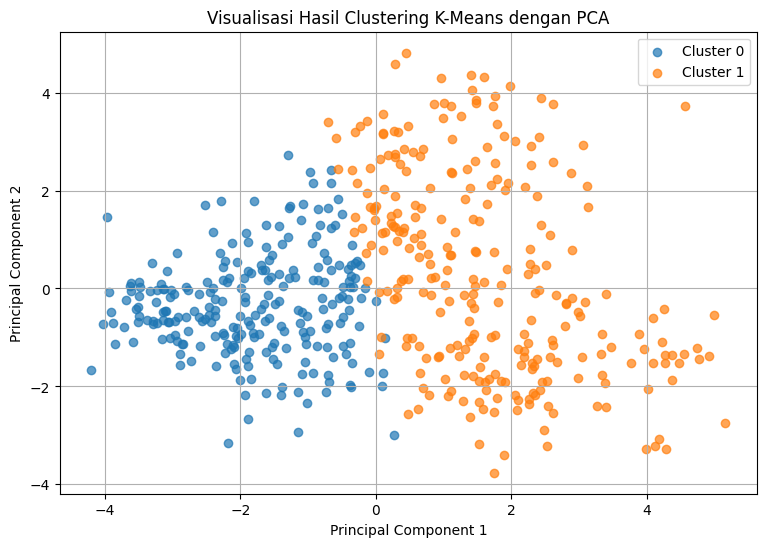

Total variasi yang dijelaskan PCA: 29.58 %


In [40]:

# ==========================================
# VISUALISASI CLUSTER DENGAN PCA
# ==========================================

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

data_pca = pca.fit_transform(df_scaled)

df_visualisasi = pd.DataFrame({
    "PCA 1": data_pca[:, 0],
    "PCA 2": data_pca[:, 1],
    "Cluster": label_final
})

plt.figure(figsize=(9, 6))

for cluster in sorted(df_visualisasi["Cluster"].unique()):
    data = df_visualisasi[
        df_visualisasi["Cluster"] == cluster
    ]

    plt.scatter(
        data["PCA 1"],
        data["PCA 2"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.title("Visualisasi Hasil Clustering K-Means dengan PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)
plt.show()

print(
    "Total variasi yang dijelaskan PCA:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [41]:

# ==========================================
# PROFIL RATA-RATA KONSUMSI BUAH
# ==========================================

df_profil = df_outlier.copy()

df_profil["Cluster"] = label_final

profil_cluster = df_profil.groupby("Cluster")[fitur].mean()

print("Rata-rata konsumsi buah setiap cluster:")
display(profil_cluster.round(4))

Rata-rata konsumsi buah setiap cluster:


,"Jeruk, jeruk bali",Mangga,Apel,Rambutan,"Duku, langsat",Durian,Salak,Pisang ambon,Pisang lainnya,Pepaya,...,Nanas,Nangka,Pir,Anggur,Buah naga,Jambu air,Melon,Manggis,Kelengkeng,Buah-buahan lainnya
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.0246,0.0176,0.0113,0.0775,0.0264,0.0337,0.0153,0.0318,0.1451,0.0618,...,0.0103,0.0049,0.0054,0.0038,0.0121,0.0032,0.0022,0.0025,0.0041,0.0130
1,0.0832,0.0090,0.0168,0.1067,0.0473,0.0243,0.0424,0.0389,0.1014,0.0756,...,0.0090,0.0038,0.0171,0.0081,0.0231,0.0046,0.0054,0.0050,0.0078,0.0104


In [ ]:

# ==========================================
# LIMA BUAH DENGAN RATA-RATA TERTINGGI
# PADA SETIAP CLUSTER
# ==========================================

for cluster in profil_cluster.index:

    print(f"\nCluster {cluster}")

    lima_tertinggi = (
        profil_cluster.loc[cluster]
        .sort_values(ascending=False)
        .head(5)
    )

    display(lima_tertinggi.to_frame(
        name="Rata-rata Konsumsi"
    ).round(4))

In [ ]:

# ==========================================
# DAFTAR KABUPATEN/KOTA BERDASARKAN CLUSTER
# ==========================================

for cluster in sorted(hasil_cluster["Cluster"].unique()):

    print(f"\nDAFTAR KABUPATEN/KOTA - CLUSTER {cluster}")

    anggota = hasil_cluster[
        hasil_cluster["Cluster"] == cluster
    ]

    display(anggota.reset_index(drop=True))

Setelah proses clustering menggunakan algoritma K-Means dilakukan, tahap selanjutnya adalah menginterpretasikan karakteristik dari setiap cluster yang terbentuk. Interpretasi dilakukan dengan membandingkan nilai rata-rata konsumsi dari 24 jenis buah pada masing-masing cluster.

Perbandingan tersebut bertujuan untuk mengetahui jenis buah yang memiliki rata-rata konsumsi relatif lebih tinggi maupun lebih rendah pada setiap kelompok kabupaten/kota. Hasil perbandingan kemudian digunakan sebagai dasar dalam memberikan nama atau kategori pada masing-masing cluster.

Pemberian nama cluster dilakukan berdasarkan pola konsumsi buah yang menjadi karakteristik kelompok tersebut, sehingga nama yang diberikan dapat menggambarkan kondisi setiap kelompok secara lebih mudah dipahami. Dengan demikian, hasil clustering tidak hanya menunjukkan pengelompokan kabupaten/kota berdasarkan kemiripan pola konsumsi buah, tetapi juga memberikan gambaran mengenai karakteristik konsumsi buah pada setiap kelompok.


Evaluasi model dilakukan menggunakan Silhouette Score untuk mengetahui kualitas pengelompokan yang dihasilkan oleh algoritma K-Means. Selain itu, visualisasi PCA digunakan untuk menggambarkan persebaran anggota cluster dalam dua dimensi.

Selanjutnya, dilakukan analisis profil cluster dengan menghitung rata-rata konsumsi setiap jenis buah pada masing-masing kelompok. Analisis ini bertujuan untuk mengetahui karakteristik pola konsumsi buah dari kabupaten/kota yang berada dalam kelompok yang sama.

Berdasarkan hasil tersebut, setiap cluster akan diberikan interpretasi sesuai karakteristik konsumsi buah yang dominan.

### 6.1 Kesimpulan

Berdasarkan penelitian yang telah dilakukan, dapat disimpulkan bahwa algoritma K-Means dapat digunakan untuk mengelompokkan kabupaten/kota berdasarkan pola konsumsi buah-buahan. Dataset yang digunakan bersumber dari Badan Pusat Statistik (BPS) tahun 2025 dengan jumlah 514 data kabupaten/kota dan 24 fitur jenis buah.

Sebelum proses pemodelan, dilakukan beberapa tahapan preprocessing, yaitu penanganan missing value menggunakan median, pemeriksaan data duplikat, identifikasi dan penanganan outlier menggunakan metode Interquartile Range (IQR), serta standardisasi data menggunakan StandardScaler.

Pemodelan dilakukan menggunakan algoritma K-Means dengan variasi jumlah cluster dari k=2 hingga k=8. Pengujian dilakukan pada data tanpa scaling dan data dengan scaling. Penentuan jumlah cluster mempertimbangkan nilai inertia melalui metode Elbow dan nilai Silhouette Score.

Hasil pengelompokan kemudian dianalisis berdasarkan rata-rata konsumsi setiap jenis buah untuk mengetahui karakteristik masing-masing kelompok kabupaten/kota. Dengan demikian, penelitian ini dapat memberikan gambaran mengenai kemiripan dan perbedaan pola konsumsi buah-buahan antarwilayah berdasarkan data yang digunakan.